# 02 · Análisis exploratorio de datos (EDA)
**Proyecto final · Análisis de datos, BI y aprendizaje computacional**

**Objetivo:** entender cómo se comportan los suscriptores y qué distingue a quienes **no renuevan** (churn a 90 días), antes de construir el dashboard y los modelos.

Se trabaja en dos niveles:
- **Panel mensual** (`fact_snapshot_mensual`): un usuario en un mes. Sirve para describir la plataforma y su comportamiento.
- **Ciclo** (`fact_ciclo` + variables de comportamiento): un ciclo de suscripción. Es el nivel donde está la variable a predecir.

**Regla para evitar fugas de información:** el ciclo se observa **60 días antes de su vencimiento** (momento en que comercial todavía puede actuar) y solo se usan datos anteriores a esa fecha. Además se excluyen los usuarios que **ya pagaron** la renovación a esa fecha, porque no hay nada que predecir. El churn base es alto, así que el análisis se centra en qué distingue a unos usuarios de otros, no en el promedio.

In [8]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RAIZ = Path("..").resolve()
sys.path.append(str(RAIZ))
from src import features

PROC = RAIZ / "data" / "processed"
FIG = RAIZ / "resultados" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
HORIZONTE = 60
AZUL, ROJO, GRIS = "#2F6DB5", "#B3261E", "#8A94A0"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200, "display.max_columns", 60)

snap = pd.read_csv(PROC / "fact_snapshot_mensual.csv", parse_dates=["fecha", "fecha_ultima_renovacion", "fecha_vencimiento_membresia"])
ciclos = pd.read_csv(PROC / "fact_ciclo.csv", dtype={"productoid": str, "ordenid": str},
                     parse_dates=["ciclo_inicio", "ciclo_fin", "fecha_pago", "inicio_renovacion", "fecha_pago_renovacion"])
dim_usr = pd.read_csv(PROC / "dim_usuario.csv", parse_dates=["primer_mes", "ultimo_mes", "primera_orden"])
cat = pd.read_csv(PROC / "dim_categoria.csv").set_index("categoria_id")["categoria"]
snap["categoria"] = snap["categoria_id"].map(cat)
base = features.base_horizonte(snap, ciclos, HORIZONTE)
base["categoria"] = base["categoria_id"].map(cat)
print(f"Panel mensual: {snap.shape} | Ciclos principales observables a {HORIZONTE} días: {len(base):,} | Churn a 90 días: {base['churn90'].mean():.1%}")

Panel mensual: (734944, 44) | Ciclos principales observables a 60 días: 66,417 | Churn a 90 días: 55.5%


## 1. Análisis univariado

### 1.1 Estadística descriptiva del comportamiento mensual
Media, mediana, moda, desviación, rango intercuartílico (IQR), asimetría y porcentaje de ceros. La mayoría de las variables de uso son conteos con muchos ceros.

In [9]:
uso = features.USO + ["dias_inactividad", "antiguedad_suscriptor_meses", "numero_renovaciones_usuario"]
def descriptivo(d, cols):
    t = pd.DataFrame({
        "media": d[cols].mean(), "mediana": d[cols].median(),
        "moda": d[cols].mode().iloc[0], "desv_est": d[cols].std(),
        "IQR": d[cols].quantile(.75) - d[cols].quantile(.25),
        "asimetria": d[cols].skew(), "%ceros": (d[cols] == 0).mean() * 100, "max": d[cols].max()})
    return t.round(2)
descriptivo(snap, uso)

,media,mediana,moda,desv_est,IQR,asimetria,%ceros,max
total_dias_navegacion_mes,1.27,0.0,0,2.29,2.0,3.47,54.89,31
total_apertura_boletin,7.23,1.0,0,12.27,11.0,3.37,47.49,431
total_descarga_mformatos,0.72,0.0,0,1.38,1.0,3.03,65.82,27
total_preguntas_ia,0.07,0.0,0,0.85,0.0,32.51,98.15,95
total_peticiones_calculadoras,0.03,0.0,0,0.23,0.0,19.84,97.69,24
total_peticiones_guias,0.09,0.0,0,0.43,0.0,9.95,94.01,26
total_peticiones_bookstack,0.06,0.0,0,0.40,0.0,20.58,95.98,30
total_peticiones_uamts,0.04,0.0,0,0.29,0.0,17.03,96.68,22
total_peticiones_r_actualizacion,0.37,0.0,0,1.15,0.0,5.59,83.74,28
total_solicitudes_soporte,0.06,0.0,0,0.45,0.0,11.85,97.83,32


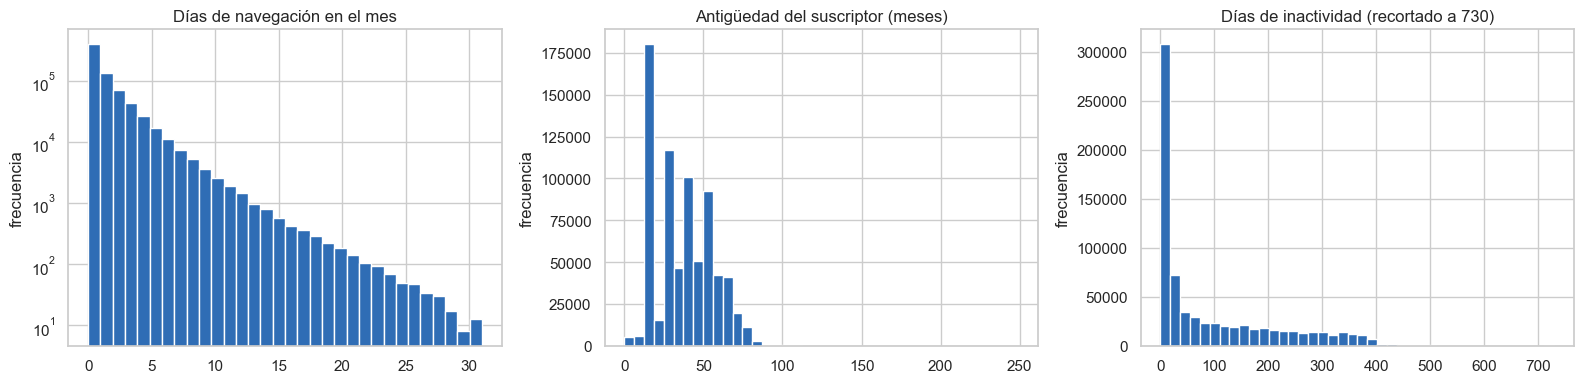

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
snap["total_dias_navegacion_mes"].plot.hist(bins=32, ax=ax[0], color=AZUL); ax[0].set_title("Días de navegación en el mes"); ax[0].set_yscale("log")
snap["antiguedad_suscriptor_meses"].plot.hist(bins=40, ax=ax[1], color=AZUL); ax[1].set_title("Antigüedad del suscriptor (meses)")
snap["dias_inactividad"].clip(upper=730).plot.hist(bins=40, ax=ax[2], color=AZUL); ax[2].set_title("Días de inactividad (recortado a 730)")
for a in ax: a.set_ylabel("frecuencia")
plt.tight_layout(); plt.savefig(FIG / "eda_univariado.png", dpi=130); plt.show()

### 1.2 Variables categóricas

In [11]:
comp = snap.groupby("categoria")["usuario_id"].agg(filas="size", usuarios="nunique")
comp["% de filas"] = (comp["filas"] / comp["filas"].sum() * 100).round(1)
display(comp)
cb = base["churn90"].value_counts(normalize=True).rename({0: "Renovó", 1: "No renovó (churn)"}).mul(100).round(1)
print("\nVariable objetivo en los ciclos maduros (%):"); print(cb.to_string())

,filas,usuarios,% de filas
categoria,,,
Básica,23991,5709,3.3
Oro,469676,27799,63.9
Platino,241277,15823,32.8



Variable objetivo en los ciclos maduros (%):
churn90
No renovó (churn)    55.5
Renovó               44.5


## 2. Evolución en el tiempo: altas, reactivaciones y bajas

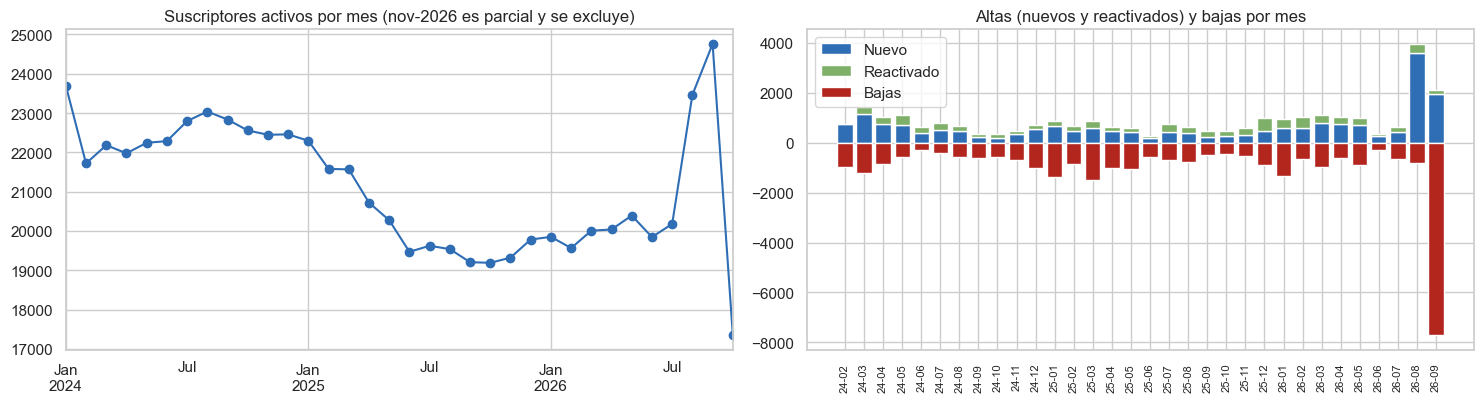

,Activos,Nuevo,Reactivado,Bajas
mean,21162.0,638.0,239.0,999.0
min,19189.0,167.0,0.0,285.0
max,24756.0,3602.0,502.0,7703.0


In [12]:
m = snap[["usuario_id", "fecha"]].copy()
m["m"] = m["fecha"].dt.year * 12 + m["fecha"].dt.month
m = m.sort_values(["usuario_id", "m"])
prev = m.groupby("usuario_id")["m"].shift(1)
nxt = m.groupby("usuario_id")["m"].shift(-1)
m["tipo"] = np.where(prev.isna(), "Nuevo", np.where(m["m"] - prev > 1, "Reactivado", "Continúa"))
m["sale"] = nxt.isna() | (nxt - m["m"] > 1)

mov = m.groupby(["fecha", "tipo"]).size().unstack(fill_value=0)
bajas = m[m["sale"]].groupby("fecha").size().rename("Bajas")
serie = pd.concat([mov, bajas], axis=1).fillna(0).astype(int)
serie["Activos"] = serie[["Continúa", "Nuevo", "Reactivado"]].sum(axis=1)
serie = serie.iloc[1:-2]     # se excluye ene-2024 (todos aparecen como nuevos) y los 2 últimos meses (no se puede saber si salieron)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
activos = snap.groupby("fecha")["usuario_id"].nunique().loc[:"2026-10-31"]
activos.plot(ax=ax[0], color=AZUL, marker="o"); ax[0].set_title("Suscriptores activos por mes (nov-2026 es parcial y se excluye)"); ax[0].set_xlabel("")
x = np.arange(len(serie))
ax[1].bar(x, serie["Nuevo"], color=AZUL, label="Nuevo")
ax[1].bar(x, serie["Reactivado"], bottom=serie["Nuevo"], color="#7FB069", label="Reactivado")
ax[1].bar(x, -serie["Bajas"], color=ROJO, label="Bajas")
ax[1].set_title("Altas (nuevos y reactivados) y bajas por mes"); ax[1].set_xlabel("")
ax[1].set_xticks(x); ax[1].set_xticklabels([d.strftime("%y-%m") for d in serie.index], rotation=90, fontsize=8); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "eda_serie_mensual.png", dpi=130); plt.show()
serie[["Activos", "Nuevo", "Reactivado", "Bajas"]].describe().loc[["mean", "min", "max"]].round(0)

## 3. Calidad de los datos: valores atípicos y reglas de negocio

In [13]:
reglas = pd.Series({
    "Días de navegación mayores a 31 (imposible en un mes)": int((snap["total_dias_navegacion_mes"] > 31).sum()),
    "Antigüedad negativa": int((snap["antiguedad_suscriptor_meses"] < 0).sum()),
    "Descuentos negativos": int((snap["valor_descuentos_cupones"] < 0).sum()),
    "Fecha de renovación posterior a la foto": int((snap["fecha_ultima_renovacion"] > snap["fecha"]).sum()),
})
display(reglas.to_frame("filas que violan la regla"))

def atipicos_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
cols = ["antiguedad_suscriptor_meses", "dias_inactividad", "valor_descuentos_cupones", "total_dias_navegacion_mes"]
pd.DataFrame({"atípicos (regla 1,5×IQR)": {c: atipicos_iqr(snap[c]) for c in cols},
              "% de filas": {c: round(atipicos_iqr(snap[c]) / len(snap) * 100, 1) for c in cols}})

,filas que violan la regla
Días de navegación mayores a 31 (imposible en un mes),0
Antigüedad negativa,0
Descuentos negativos,0
Fecha de renovación posterior a la foto,1253


,"atípicos (regla 1,5×IQR)",% de filas
antiguedad_suscriptor_meses,1923,0.3
dias_inactividad,10541,1.4
valor_descuentos_cupones,58291,7.9
total_dias_navegacion_mes,37808,5.1


### Ciclos cortos, regalos y duración atípica

In [14]:
print("Duraciones más frecuentes (días):", ciclos["duracion_dias"].value_counts().head(6).to_dict())
q = ciclos[ciclos["ciclo_inicio"] >= "2025-01-01"].assign(trimestre_inicio=lambda x: x["ciclo_inicio"].dt.to_period("Q")).groupby("trimestre_inicio").agg(
    ciclos=("ciclo_id", "size"), pct_planes_cortos_o_regalo=("grupo_producto", lambda x: round((x != "Principal").mean() * 100, 1)))
display(q.T)

# Regalos y planes cortos: ¿terminan en un plan pagado?
cortos = ciclos[(ciclos["grupo_producto"] != "Principal") | (ciclos["es_regalo"] == 1)].copy()
p = ciclos[ciclos["grupo_producto"] == "Principal"][["usuario_id", "ciclo_inicio"]].rename(columns={"ciclo_inicio": "ini_pago"})
x = cortos.merge(p, on="usuario_id", how="left")
x = x[(x["ini_pago"] >= x["ciclo_fin"] - pd.Timedelta(days=30)) & (x["ini_pago"] <= x["ciclo_fin"] + pd.Timedelta(days=90))]
cortos["pasa_a_plan_principal"] = cortos["ciclo_id"].isin(x["ciclo_id"]).astype(int)
cortos = cortos[cortos["ciclo_fin"] + pd.Timedelta(days=90) <= pd.Timestamp("2026-10-31")]
cortos["tipo"] = np.where(cortos["es_regalo"] == 1, "Regalo", "Plan corto u otro")
print("\nConversión a plan principal en los 90 días posteriores (ciclos cortos ya cerrados):")
cortos.groupby("tipo")["pasa_a_plan_principal"].agg(["mean", "size"]).round(3)

Duraciones más frecuentes (días): {365: 60200, 366: 22652, 395: 5500, 367: 5165, 92: 3276, 14: 3097}


trimestre_inicio,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4,2027Q1,2027Q2,2027Q3,2027Q4,2028Q1,2028Q2,2029Q1
ciclos,6523.0,3793.0,3870.0,4452.0,6494.0,4967.0,8931.0,3748.0,294.0,64.0,122.0,20.0,6.0,3.0,2.0
pct_planes_cortos_o_regalo,1.8,1.1,1.4,1.4,1.2,4.1,34.4,21.8,11.2,37.5,8.2,10.0,0.0,0.0,0.0



Conversión a plan principal en los 90 días posteriores (ciclos cortos ya cerrados):


,mean,size
tipo,,
Plan corto u otro,0.035,4006
Regalo,0.091,22


**Conclusión.** Las duraciones dominantes son 365 y 366 días (más de 80.000 ciclos), pero en el tercer trimestre de 2026 los planes cortos (92 y 14 días) y los regalos llegan al 34 % de los ciclos. Solo el 3,5 % de los planes cortos y el 9,1 % de los regalos pasa a un plan principal en los 90 días siguientes, por eso se sacan del modelo de churn y se analizan aparte.

## 4. Análisis bivariado frente al churn
Tasa de no renovación por segmento, con intervalo de confianza del 95 %.

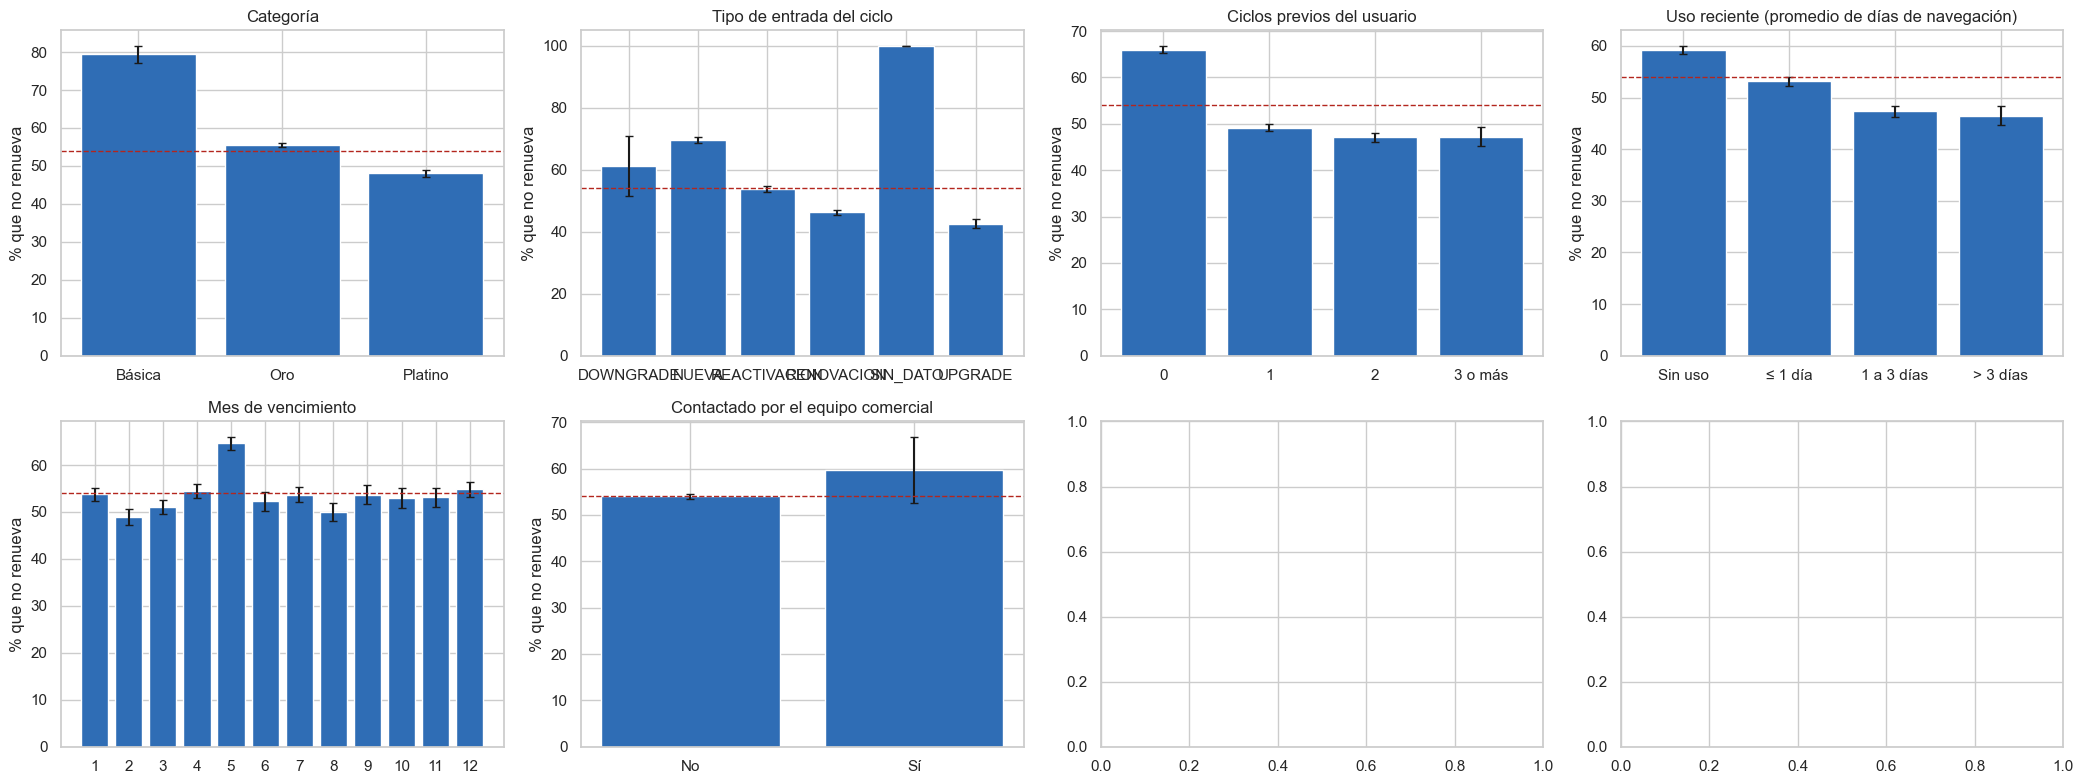

,mean,size,ic
categoria,,,
Básica,0.794,1272,0.022
Oro,0.555,27476,0.006
Platino,0.481,12041,0.009


In [15]:
d = base[base["sin_foto_previa"] == 0].copy()          # ciclos con al menos una foto previa al corte
def tasa(df, col, orden=None):
    g = df.groupby(col, observed=True)["churn90"].agg(["mean", "size"])
    g["ic"] = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    return g.reindex(orden) if orden is not None else g

d["ciclos_previos_grupo"] = d["ciclos_previos"].clip(upper=3).astype(int).astype(str).replace({"3": "3 o más"})
d["fue_contactado"] = (d["contactos_n"] > 0).astype(int)
d["contactado"] = d["fue_contactado"].map({0: "No", 1: "Sí"})
d["uso_nivel"] = pd.cut(d["nav_ult3"], [-0.01, 0, 1, 3, 40], labels=["Sin uso", "≤ 1 día", "1 a 3 días", "> 3 días"])
d["duracion_grupo"] = pd.cut(d["duracion_dias"], [0, 364, 366, 500, 5000], labels=["< 365", "365–366", "367–500", "> 500"])
paneles = [("categoria", "Categoría", ["Básica", "Oro", "Platino"]), ("tipo_entrada", "Tipo de entrada del ciclo", None), ("ciclos_previos_grupo", "Ciclos previos del usuario", None),
           ("uso_nivel", "Uso reciente (promedio de días de navegación)", None),
           ("mes_vencimiento", "Mes de vencimiento", None), ("contactado", "Contactado por el equipo comercial", None)]
fig, axes = plt.subplots(2, 4, figsize=(21, 8))
for a, (col, titulo, orden) in zip(axes.ravel(), paneles):
    t = tasa(d, col, orden)
    a.bar(t.index.astype(str), t["mean"] * 100, yerr=t["ic"] * 100, color=AZUL, capsize=3)
    a.axhline(d["churn90"].mean() * 100, color=ROJO, ls="--", lw=1)
    a.set_title(titulo); a.set_ylabel("% que no renueva"); a.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_churn_segmentos.png", dpi=130); plt.show()
tasa(d, "categoria", ["Básica", "Oro", "Platino"]).round(3)

In [16]:
print("Churn por tipo de entrada:"); display((tasa(d, "tipo_entrada")[["mean", "size"]]).round(3))
print("Churn por ciclos previos:"); display((tasa(d, "ciclos_previos_grupo")[["mean", "size"]]).round(3))
print("Churn por nivel de uso reciente:"); display((tasa(d, "uso_nivel")[["mean", "size"]]).round(3))
print("Churn según haya sido contactado:"); display((tasa(d, "fue_contactado")[["mean", "size"]]).round(3))

Churn por tipo de entrada:


,mean,size
tipo_entrada,,
DOWNGRADE,0.612,98
NUEVA,0.697,10418
REACTIVACION,0.539,11208
RENOVACION,0.463,14891
SIN_DATO,1.000,1
UPGRADE,0.426,4173


Churn por ciclos previos:


,mean,size
ciclos_previos_grupo,,
0,0.660,13252
1,0.492,15699
2,0.471,9530
3 o más,0.472,2308


Churn por nivel de uso reciente:


,mean,size
uso_nivel,,
Sin uso,0.593,16694
≤ 1 día,0.532,13120
1 a 3 días,0.473,8171
> 3 días,0.464,2804


Churn según haya sido contactado:


,mean,size
fue_contactado,,
0,0.540,40608
1,0.597,181


**Conclusión.** El churn depende sobre todo de cómo entra el suscriptor: las altas nuevas se van 70 % y las renovaciones y upgrades 43–46 %. También baja con la antigüedad (0 ciclos previos: 66 %; 1 o más: 47–49 %), con la categoría (Básica 79 %, Oro 56 %, Platino 48 %) y con el uso reciente (sin uso 59 %, más de 3 días 46 %). Los contactados parecen irse más (60 % contra 54 %), pero son pocos (181) y comercial contacta a quienes ya parecen en riesgo: no mide el efecto del contacto.

## 5. Pruebas de hipótesis
Se usa un nivel de significancia de 0,05. Para variables categóricas, **chi-cuadrado** con **V de Cramér** como tamaño del efecto; para variables numéricas muy asimétricas, **Mann-Whitney** (no asume normalidad) con la correlación biserial de rangos como tamaño del efecto.

- **H1:** la tasa de churn depende de la categoría de membresía.
- **H2:** la tasa de churn depende del tipo de entrada del ciclo (nueva, renovación, reactivación, upgrade).
- **H3:** los ciclos con menor uso reciente tienen más churn.
- **H4:** los usuarios contactados por el equipo comercial tienen una tasa de churn distinta.

In [17]:
def chi2(df, col, nombre):
    ct = pd.crosstab(df[col], df["churn90"])
    chi, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi / (ct.values.sum() * (min(ct.shape) - 1)))
    return {"hipótesis": nombre, "prueba": "chi²", "estadístico": round(chi, 1), "p-valor": p, "tamaño del efecto": round(v, 3)}

def mann(df, col, nombre):
    a, b = df.loc[df["churn90"] == 1, col].dropna(), df.loc[df["churn90"] == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b)
    return {"hipótesis": nombre, "prueba": "Mann-Whitney", "estadístico": round(u, 0), "p-valor": p,
            "tamaño del efecto": round(2 * u / (len(a) * len(b)) - 1, 3)}

res = pd.DataFrame([chi2(d, "categoria", "H1 categoría"), chi2(d, "tipo_entrada", "H2 tipo de entrada"),
                    mann(d, "nav_ult3", "H3 uso reciente"), chi2(d, "fue_contactado", "H4 contactado")])
res["¿significativa?"] = np.where(res["p-valor"] < 0.05, "Sí", "No")
res["p-valor"] = res["p-valor"].map(lambda x: f"{x:.2e}")
res

,hipótesis,prueba,estadístico,p-valor,tamaño del efecto,¿significativa?
0,H1 categoría,chi²,524.2,1.50e-114,0.113,Sí
1,H2 tipo de entrada,chi²,1600.9,0.00e+00,0.198,Sí
2,H3 uso reciente,Mann-Whitney,183218376.0,1.78e-93,-0.113,Sí
3,H4 contactado,chi²,2.1,1.47e-01,0.007,No


**Conclusión.** Se rechaza la independencia en H1 (categoría, V = 0,113), H2 (tipo de entrada, V = 0,198) y H3 (uso reciente, r = −0,113), todas con p < 0,001 y efectos pequeños a moderados; el tipo de entrada es el factor más fuerte. En H4 no hay diferencia significativa entre contactados y no contactados (p = 0,147). Con muestras tan grandes casi todo sale «significativo», por eso se reporta también el tamaño del efecto.

## 6. Análisis multivariado

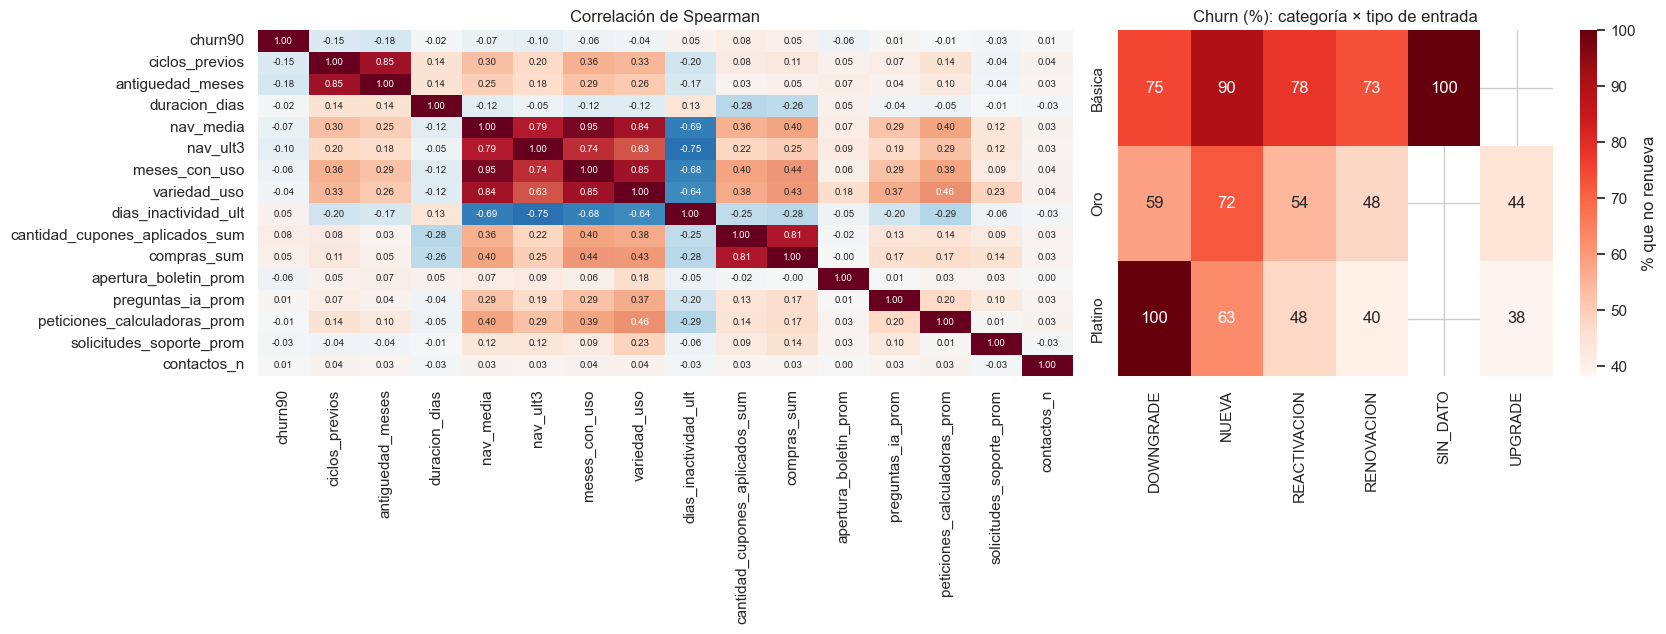

,Spearman con churn90
antiguedad_meses,-0.177
ciclos_previos,-0.151
nav_ult3,-0.102
nav_media,-0.068
apertura_boletin_prom,-0.060
meses_con_uso,-0.060
variedad_uso,-0.037
solicitudes_soporte_prom,-0.030
duracion_dias,-0.021
peticiones_calculadoras_prom,-0.012


In [18]:
num = ["churn90", "ciclos_previos", "antiguedad_meses", "duracion_dias", "nav_media", "nav_ult3", "meses_con_uso",
       "variedad_uso", "dias_inactividad_ult", "cantidad_cupones_aplicados_sum", "compras_sum", "apertura_boletin_prom",
       "preguntas_ia_prom", "peticiones_calculadoras_prom", "solicitudes_soporte_prom", "contactos_n"]
corr = d[num].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False, annot_kws={"size": 7})
ax[0].set_title("Correlación de Spearman")
pv = d.pivot_table(index="categoria", columns="tipo_entrada", values="churn90", aggfunc="mean").reindex(["Básica", "Oro", "Platino"]) * 100
sns.heatmap(pv, annot=True, fmt=".0f", cmap="Reds", ax=ax[1], cbar_kws={"label": "% que no renueva"})
ax[1].set_title("Churn (%): categoría × tipo de entrada"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_multivariado.png", dpi=130); plt.show()
corr["churn90"].drop("churn90").sort_values().round(3).to_frame("Spearman con churn90")

## 7. Control de fuga de información
Una variable puede parecer muy predictiva solo porque se registra **después** del hecho que queremos predecir. Se compara la correlación con el churn usando fotos hasta el vencimiento (0 días antes) y fotos hasta 60 días antes. Si una variable se vuelve mucho más "predictiva" al acercarse al vencimiento, probablemente refleja el acto de renovar y no el comportamiento previo.

In [19]:
base0 = features.base_horizonte(snap, ciclos, 0)
base0["fue_contactado"] = (base0["contactos_n"] > 0).astype(int)
vars_ = ["nav_ult3", "dias_inactividad_ult", "cantidad_cupones_aplicados_sum", "compras_sum", "fue_contactado", "antiguedad_meses"]
def sp(df, v):
    x = df.dropna(subset=[v, "churn90"]); return stats.spearmanr(x[v], x["churn90"])[0]
fuga = pd.DataFrame({"hasta el vencimiento (0 d)": {v: sp(base0, v) for v in vars_},
                     "60 días antes": {v: sp(d, v) for v in vars_}}).round(3)
fuga["cambio"] = (fuga["60 días antes"] - fuga["hasta el vencimiento (0 d)"]).round(3)
fuga

,hasta el vencimiento (0 d),60 días antes,cambio
nav_ult3,-0.098,-0.102,-0.004
dias_inactividad_ult,0.076,0.047,-0.029
cantidad_cupones_aplicados_sum,0.056,0.075,0.019
compras_sum,0.042,0.053,0.011
fue_contactado,0.014,0.008,-0.006
antiguedad_meses,-0.119,-0.177,-0.058


**Conclusión.** Ninguna variable se vuelve mucho más «predictiva» al acercarse al vencimiento (cambios de −0,06 a +0,02), por lo que no hay señales de fuga: las variables describen comportamiento previo y no el acto de renovar. Se mantiene la regla de observar el ciclo 60 días antes y excluir a quienes ya pagaron.

**Conclusión del EDA.** El churn depende más del contexto del ciclo (tipo de entrada, plan, antigüedad) que del uso: las correlaciones del uso con el churn son débiles (−0,07 a −0,10). Ninguna variable separa por sí sola a quienes se van de quienes se quedan, así que el modelo del notebook 03 debe combinar contexto y comportamiento y demostrar que aporta más allá del tipo de entrada.